# 05 · When waiting counts: timetable routing

The static graph (notebooks 02–04) gives each stop pair one *median* travel time. It never waits for a bus, so it can't see:
- the time you spend waiting for the first bus
- the time a transfer costs
- that service is less frequent at night
- a route running less often, or running late

This notebook routes over the **actual timetable**, every scheduled departure, using the **Connection Scan Algorithm** (`transitshock.csa`). Travel times are door-to-door for a rider who shows up at a stop at a given time.

**Two kinds of stop disruption** (`transitshock.timetable.disrupt`):
- **Closed:** buses drive past without stopping, so riders can't board or alight there.
- **Blocked:** nothing can pass, like a road closure. Each trip is split at that point. This is what removing a node from the static graph means.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from transitshock import csa
from transitshock.build_graph import load_graph
from transitshock.load_gtfs import load_feed
from transitshock.scenario import baseline, impact, timetable_baseline, timetable_impact
from transitshock.timetable import build_timetable, disrupt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FIGURES = ROOT / "figures"

G = load_graph(ROOT / "data" / "processed" / "lbt_20261104.gpickle")
tt = build_timetable(load_feed(ROOT / "data" / "raw" / "lbt", "20261104"), "lbt", G)
crit = pd.read_csv(ROOT / "app" / "data" / "lbt_critical.csv", index_col="node")
pd.Series({
    "stops": tt.n_stops,
    "trips": tt.n_trips,
    "connections (bus hops)": len(tt),
    "walking transfers (≤200 m)": len(tt.foot_to),
})

stops                          1853
trips                          1914
connections (bus hops)        89782
walking transfers (≤200 m)     4182
dtype: int64

In [2]:
%%time
# Every stop x every 15 minutes from 7-9 AM = one morning-peak "baseline".
am = timetable_baseline(tt, "07:00", "09:00", every_min=15)
print(f"{len(am.sources):,} door-to-door queries")
pd.Series(am.metrics).round(4)

14,824 door-to-door queries
CPU times: user 2.83 s, sys: 299 ms, total: 3.13 s
Wall time: 2.23 s


efficiency          0.0234
reachable_share     0.9945
mean_time_min      56.6405
dtype: float64

## 1. How much does waiting add?

In [3]:
static = baseline(G)
static_min = static.dist / 60
static_min[~np.isfinite(static_min)] = np.nan

# Timetable minutes per (source, destination), averaged over the departure times.
tt_min = pd.DataFrame(am.minutes).groupby(am.sources).mean().to_numpy().copy()
np.fill_diagonal(static_min, np.nan)
np.fill_diagonal(tt_min, np.nan)
both = np.isfinite(static_min) & np.isfinite(tt_min)

extra = (tt_min - static_min)[both]
pd.Series({
    "static mean trip (min)": static_min[both].mean(),
    "timetable mean trip (min)": tt_min[both].mean(),
    "ratio": tt_min[both].mean() / static_min[both].mean(),
    "median extra minutes from waiting": np.median(extra),
    "pairs where timetable is faster": (extra < -0.01).mean(),
}).round(3)

static mean trip (min)               28.634
timetable mean trip (min)            56.643
ratio                                 1.978
median extra minutes from waiting    26.330
pairs where timetable is faster       0.000
dtype: float64

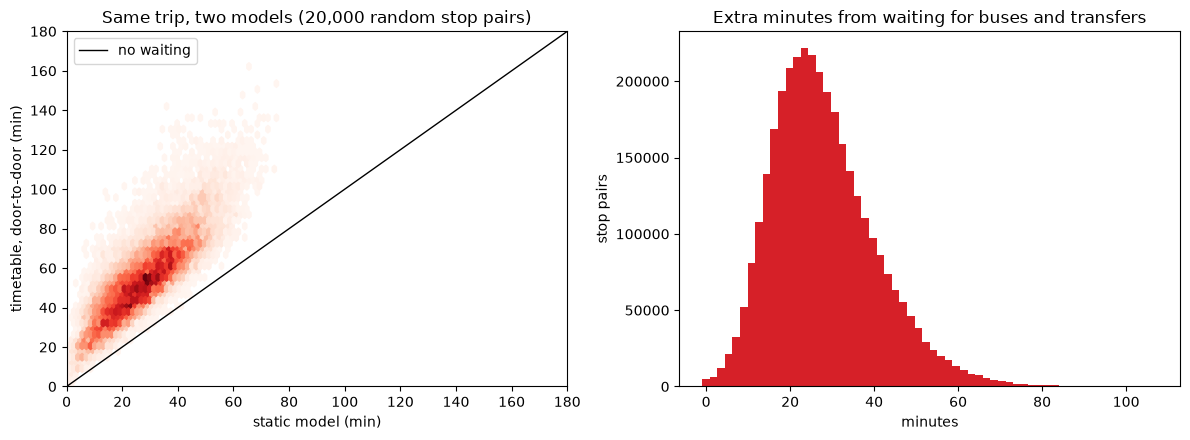

In [4]:
rng = np.random.default_rng(0)
idx = rng.choice(both.sum(), 20000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hexbin(static_min[both][idx], tt_min[both][idx], gridsize=50, cmap="Reds", mincnt=1)
lim = [0, 180]
axes[0].plot(lim, lim, color="black", lw=1, label="no waiting")
axes[0].set(xlim=lim, ylim=lim, xlabel="static model (min)", ylabel="timetable, door-to-door (min)",
            title="Same trip, two models (20,000 random stop pairs)")
axes[0].legend()
axes[1].hist(extra, bins=60, color="#D62028")
axes[1].set(title="Extra minutes from waiting for buses and transfers", xlabel="minutes", ylabel="stop pairs")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_static_vs_timetable.png", dpi=150)

## 2. Time of day

The same network is a different network at 10 PM. Below, every stop is queried every 30 minutes through the day. "Reachable" means you arrive within 3 hours.

In [5]:
%%time
rows = []
for hour in range(5, 24):
    for minute in (0, 30):
        t = f"{hour:02d}:{minute:02d}"
        s, t0 = csa.departure_grid(np.arange(tt.n_stops), t, f"{hour:02d}:{minute + 1:02d}", 1)
        rows.append({"time": hour + minute / 60, **csa.summarize(csa.travel_times(tt, s, t0), s, tt.n_stops)})
by_time = pd.DataFrame(rows)

CPU times: user 3.72 s, sys: 61.5 ms, total: 3.79 s
Wall time: 881 ms


,time,efficiency,reachable_share,mean_time_min
0,5.0,0.018,0.995,73.458
4,7.0,0.023,0.994,56.972
8,9.0,0.023,0.994,56.450
12,11.0,0.023,0.994,57.910
16,13.0,0.023,0.994,58.555
20,15.0,0.022,0.995,60.638
24,17.0,0.022,0.995,60.191
28,19.0,0.021,0.946,60.594
32,21.0,0.014,0.613,62.071
36,23.0,0.005,0.132,56.792


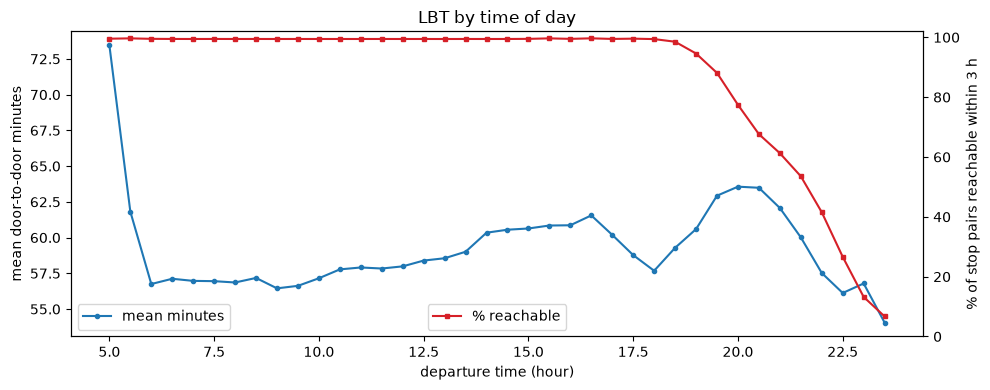

In [6]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(by_time["time"], by_time["mean_time_min"], color="#1f77b4", marker="o", ms=3)
ax1.set(xlabel="departure time (hour)", ylabel="mean door-to-door minutes", title="LBT by time of day")
ax2 = ax1.twinx()
ax2.plot(by_time["time"], 100 * by_time["reachable_share"], color="#D62028", marker="s", ms=3)
ax2.set(ylabel="% of stop pairs reachable within 3 h", ylim=(0, 102))
ax1.legend(["mean minutes"], loc="lower left")
ax2.legend(["% reachable"], loc="lower center")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_time_of_day.png", dpi=150)
by_time.iloc[::4].round(3)

## 3. Disruptions: static vs. timetable, closed vs. blocked

All scenarios use the 7–9 AM peak. "Static" is the Week 3 model, which can only represent blockages and route cancellations.

In [7]:
%%time
top10 = crit.nsmallest(10, "predicted_rank").index.tolist()
busy10 = sorted(G, key=lambda n: -G.nodes[n]["trips_per_day"])[:10]
busiest_route = tt.events.groupby("route")["trip"].nunique().idxmax()

scenarios = {
    "block model's top-10 critical stops": (dict(stops=top10), dict(blocked_stops=top10)),
    "block 10 busiest stops": (dict(stops=busy10), dict(blocked_stops=busy10)),
    "close model's top-10 (buses skip)": (None, dict(stops=top10)),
    "close 10 busiest (buses skip)": (None, dict(stops=busy10)),
    "cancel route 71": (dict(routes=["71"]), dict(canceled_routes=["71"])),
    "halve route 71 frequency": (None, dict(reduced_routes=["71"])),
    f"halve route {busiest_route} (busiest) frequency": (None, dict(reduced_routes=[busiest_route])),
    "route 71 runs 10 min late": (None, dict(delays_min={"71": 10})),
}
rows = {}
for name, (static_kw, tt_kw) in scenarios.items():
    s, _ = timetable_impact(am, **tt_kw)
    rows[name] = {
        "static: efficiency change %": 100 * impact(G, static, **static_kw)[0]["efficiency_change"] if static_kw else np.nan,
        "timetable: efficiency change %": 100 * s["efficiency_change"],
        "timetable: + mean minutes": s["mean_time_after_min"] - s["mean_time_before_min"],
        "stops cut off": s["stops_cut_off"],
        "stops slower": s["stops_slower"],
    }
scenario_table = pd.DataFrame(rows).T.round(2)
scenario_table

CPU times: user 11.5 s, sys: 292 ms, total: 11.8 s
Wall time: 4.85 s


,static: efficiency change %,timetable: efficiency change %,timetable: + mean minutes,stops cut off,stops slower
block model's top-10 critical stops,-4.73,-5.78,0.20,44.0,395.0
block 10 busiest stops,-1.44,-2.53,0.74,0.0,111.0
close model's top-10 (buses skip),NaN,-1.65,0.45,0.0,88.0
close 10 busiest (buses skip),NaN,-1.87,0.30,0.0,37.0
cancel route 71,-7.63,-7.41,0.26,75.0,33.0
halve route 71 frequency,NaN,-1.48,1.12,0.0,100.0
halve route 61 (busiest) frequency,NaN,-0.92,0.39,0.0,78.0
route 71 runs 10 min late,NaN,-0.07,0.06,0.0,30.0


In [8]:
# The same blockage at different times of day.
windows = {"morning peak 7-9": ("07:00", "09:00"), "midday 11-13": ("11:00", "13:00"), "evening 20-22": ("20:00", "22:00")}
pd.DataFrame({
    w: {k: v for k, v in timetable_impact(timetable_baseline(tt, a, b), blocked_stops=top10)[0].items()
        if k in ("efficiency_change", "stops_cut_off", "stops_slower")}
    for w, (a, b) in windows.items()
}).T.round(4)

,efficiency_change,stops_cut_off,stops_slower
morning peak 7-9,-0.0578,44.0,395.0
midday 11-13,-0.0597,44.0,440.0
evening 20-22,-0.0631,99.0,579.0


## 4. Do the critical stops change when waiting counts?

The Week 4 model was trained on static damage. Here, single-stop damage is recomputed on the timetable for a sample of stops: the 100 most damaging under the static model, plus 200 random ones. It's done both ways, blocked and closed, using departures every 30 minutes from 7–9 AM.

In [9]:
%%time
src, t0 = csa.departure_grid(np.arange(tt.n_stops), "07:00", "09:00", 30)
base_eff = csa.summarize(csa.travel_times(tt, src, t0), src, tt.n_stops)["efficiency"]
sample = list(dict.fromkeys(crit.nsmallest(100, "true_rank").index.tolist()
                            + list(np.random.default_rng(0).choice(crit.index, 200, replace=False))))
rows = {}
for node in sample:
    removed = np.zeros(tt.n_stops, dtype=bool)
    removed[tt.stops.index(node)] = True
    for mode, kw in [("blocked", dict(blocked_stops=[node])), ("closed", dict(closed_stops=[node]))]:
        m = csa.travel_times(disrupt(tt, **kw), src, t0)
        rows.setdefault(node, {})[f"timetable {mode}"] = 1 - csa.summarize(m, src, tt.n_stops, removed)["efficiency"] / base_eff
single = pd.DataFrame(rows).T
single["static (Week 4 label)"] = crit.loc[single.index, "efficiency_loss"]
single["model prediction"] = crit.loc[single.index, "predicted"]
single.corr(method="spearman").round(2)

CPU times: user 5min 35s, sys: 1.8 s, total: 5min 37s
Wall time: 1min 15s


,timetable blocked,timetable closed,static (Week 4 label),model prediction
timetable blocked,1.00,0.40,0.74,0.72
timetable closed,0.40,1.00,0.27,0.28
static (Week 4 label),0.74,0.27,1.00,0.92
model prediction,0.72,0.28,0.92,1.00


Of the top 15 stops under timetable-blocked damage:
  6 are also top 15 under static damage
  3 are also top 15 by the model


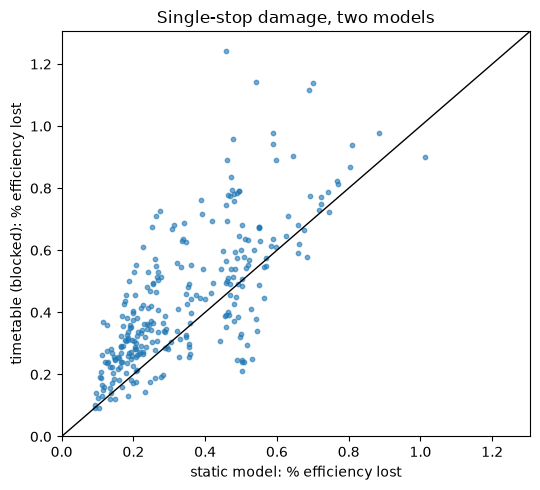

In [10]:
k = 15
top = lambda col: set(single.nlargest(k, col).index)
print(f"Of the top {k} stops under timetable-blocked damage:")
print(f"  {len(top('timetable blocked') & top('static (Week 4 label)'))} are also top {k} under static damage")
print(f"  {len(top('timetable blocked') & top('model prediction'))} are also top {k} by the model")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(100 * single["static (Week 4 label)"], 100 * single["timetable blocked"], s=10, alpha=0.6)
lim = [0, 100 * single[["static (Week 4 label)", "timetable blocked"]].max().max() * 1.05]
ax.plot(lim, lim, color="black", lw=1)
ax.set(xlim=lim, ylim=lim, xlabel="static model: % efficiency lost", ylabel="timetable (blocked): % efficiency lost",
       title="Single-stop damage, two models")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_single_stop_static_vs_timetable.png", dpi=150)

## Findings

**Speed:** the Connection Scan Algorithm (CSA), compiled with numba, answers one "leave stop X at time T" query in about 0.05 ms. A full morning-peak baseline (every stop × 8 departure times = 14,824 queries over 89,782 bus hops) takes about 0.2 s once compiled. That's fast enough to recompute on every click in the app.

**1. Waiting doubles travel time.** In the 7–9 AM peak, the average door-to-door trip between two stops takes **56.6 minutes**, versus **28.6** in the static model (1.98×). The median pair gets 26 extra minutes from waiting for the first bus and for transfers. The timetable is never faster than the static model for any pair, which is a good consistency check.

**2. Time of day matters a lot.**
- **Daytime:** from 7 AM to 5 PM the network is stable, at about 57–61 minutes average with 99% of stop pairs reachable within 3 hours.
- **5 AM:** service is ramping up, so the average trip takes 73 minutes.
- **Evening:** reachability collapses as routes stop running: 95% at 7 PM, 61% at 9 PM, and **13% at 11 PM**.

**3. "Closed" and "blocked" are different disruptions, and the static model only captures blocked.** Morning peak:

| Scenario | Static | Timetable | Stops cut off |
|---|---|---|---|
| Block the model's top-10 critical stops | −4.7% | **−5.8%** | 44 |
| Block the 10 busiest stops | −1.4% | −2.5% | 0 |
| Close the model's top-10 (buses skip) | — | −1.7% | 0 |
| Close the 10 busiest (buses skip) | — | −1.9% | 0 |
| Cancel route 71 | −7.6% | −7.4% | 75 |
| Halve route 71's frequency | — | −1.5% | 0 |
| Route 71 runs 10 min late | — | −0.1% | 0 |

- **Blocking:** the static model's critical stops are exactly the right targets. The timetable cuts off the same 44 stops, and damage is about 20% higher once waiting counts.
- **Closing (buses skip):** much milder, because the route keeps running past. Busy stops matter slightly *more* than "critical" ones here, since the damage falls on the riders who use that stop rather than on anyone passing through.
- **Frequency cuts:** halving a route costs about as much as closing 10 stops, and nobody gets cut off; trips just get longer. The static model can't represent this at all.
- **Uniform delays barely matter:** if a route runs 10 minutes late, every bus on it shifts together, so only a few transfers break.

**4. Evening blockages hurt more.** Blocking the same 10 stops costs 5.8% of efficiency in the morning, 6.0% at midday, and **6.3% in the evening**, and cuts off **99** stops instead of 44. With fewer buses running, there are fewer ways around a blockage.

**5. Critical stops partly change once waiting counts.** On a sample of 283 stops (the 100 most damaging under the static model, plus random ones):
- For blockages, static and timetable damage agree reasonably well (Spearman ρ = 0.74).
- But only 6 of the timetable's top 15 stops are also in the static top 15, and only 3 are in the model's top 15.
- For closures (buses skip), damage barely matches the static ranking (ρ = 0.27). It's a different question and would need its own model.

**Takeaway:** the static model is a good, fast screening tool for blockages, but the timetable is the more faithful one. The natural next step for the model is to train it on timetable labels: about 4–5 minutes for all 1,853 stops at the current speed.